# Prediction using mrcnn-fpn model

reference:
- Model: Mask R-CNN, Kaiming He and Georgia Gkioxari and Piotr Dollár and Ross Girshick,2018, arXiv,cs.CV,https://arxiv.org/abs/1703.06870
- Model: Benchmarking detection transfer learning with vision transformers. Y Li, S Xie, X Chen, P Dollar, K He, R Girshick
arXiv preprint arXiv:2111.11429, 2021


In [1]:
import torch
import os
import cv2
import numpy as np
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2,MaskRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import io
from tqdm import tqdm
import matplotlib.pyplot as plt
from src.load_mrcnn import *

In [2]:
GPU_ID = 0 # GPUnumber to be used
DEVICE = torch.device(f'cuda:{GPU_ID}' if torch.cuda.is_available() else 'cpu')

image_size = 256  # choice is 256 or 512
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 5e-4
BATCH_SIZE = 8 # choice is 64 or 8
NUM_EPOCHS = 100
NUM_WORKERS = 4

sp = "exostr"

CHECKPOINT_FILE = f"256_{sp}_700_epoch.tar" # name checkpoint file here
PIN_MEMORY = True
SAVE_MODEL = False
LOAD_MODEL = True

TEST_DIR = f'dataset/{sp}/png_'+str(image_size)+'/image/test'
IMAGE_SIZE = [256,256] # [512, 512] for 512 data

#### model used is the improved version of Mask-RCNN-FPN.v2

In [3]:
def get_model():
    model = maskrcnn_resnet50_fpn_v2(weights=MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT,\
                                     box_detections_per_img = 200) #pretrained=True
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(
            in_features, num_classes=1+4) 
    model.to(DEVICE)
    
    return model

In [4]:
def save_checkpoint(state, filename='./checkpoint/'+str(image_size)+'_mask_rcnn.pth.tar'):
    print("=> Model improved, Saving checkpoint")
    torch.save(state, filename)

In [5]:
def load_checkpoint(checkpoint, model, optimizer, lr):
    print("=> Loading checkpoint")
    model.load_state_dict(checkpoint["state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer"])

    # If we don't do this then it will just have learning rate of old checkpoint
    # and it will lead to many hours of debugging \:
    for param_group in optimizer.param_groups:
        param_group["lr"] = lr

In [6]:
model = get_model()
optimizer = torch.optim.AdamW(params=model.parameters(),
                                  lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY
                                  )

In [7]:
if LOAD_MODEL and CHECKPOINT_FILE in os.listdir('./model'):
    print("Loading checkpoint")
    c_f = os.path.join('./model',CHECKPOINT_FILE)
    load_checkpoint(torch.load(c_f), model, optimizer, LEARNING_RATE)

Loading checkpoint


/tmp/ipykernel_433947/1593808751.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  load_checkpoint(torch.load(c_f), model, optimizer, LEARNING_RATE)


=> Loading checkpoint


In [8]:
import numpy as np
import torch
import cv2
from skimage.segmentation import expand_labels

def predict_multi_frame(model, frame, IMAGE_SIZE, score=0.7, msk_prob=0.7,
                        DEVICE="cuda" if torch.cuda.is_available() else "cpu"):
    # === 入力画像の前処理 ===
    images = cv2.resize(frame, IMAGE_SIZE, cv2.INTER_LINEAR) / 255.0
    images = torch.as_tensor(images, dtype=torch.float32).unsqueeze(0)  # [1, H, W, C]
    images = images.permute(0, 3, 1, 2)  # [1, C, H, W]
    images = [image.to(DEVICE) for image in images]

    # === 推論 ===
    with torch.no_grad():
        pred = model(images)

    # === ラベル→グレイ値マッピング定義 ===
    label_to_gray = {1: 63, 2: 127, 3: 191, 4: 255}

    # === 空のラベル画像を作成（整数IDとして保持）===
    height, width = images[0].shape[1:]
    im_label = np.zeros((height, width), dtype=np.uint8)

    for i in range(len(pred[0]['masks'])):
        mask_tensor = pred[0]['masks'][i]
        score_val = pred[0]['scores'][i].item()
        label_val = pred[0]['labels'][i].item()

        # スコアしきい値と対象ラベルのみ使用
        if score_val > score and label_val in label_to_gray:
            msk = mask_tensor[0].detach().cpu().numpy() if mask_tensor.ndim == 3 else mask_tensor.detach().cpu().numpy()
            im_label[msk > msk_prob] = label_val

    # === ラベルを拡張（整数で安全に拡張）===
    im_label_expanded = expand_labels(im_label, distance=1)

    # === グレイレベルに変換（明示的かつ安全）===
    vectorized = np.vectorize(lambda x: label_to_gray.get(x, 0))
    im_gray = vectorized(im_label_expanded).astype(np.uint8)

    return im_gray


You have  24  test images, and you selected image No.  2


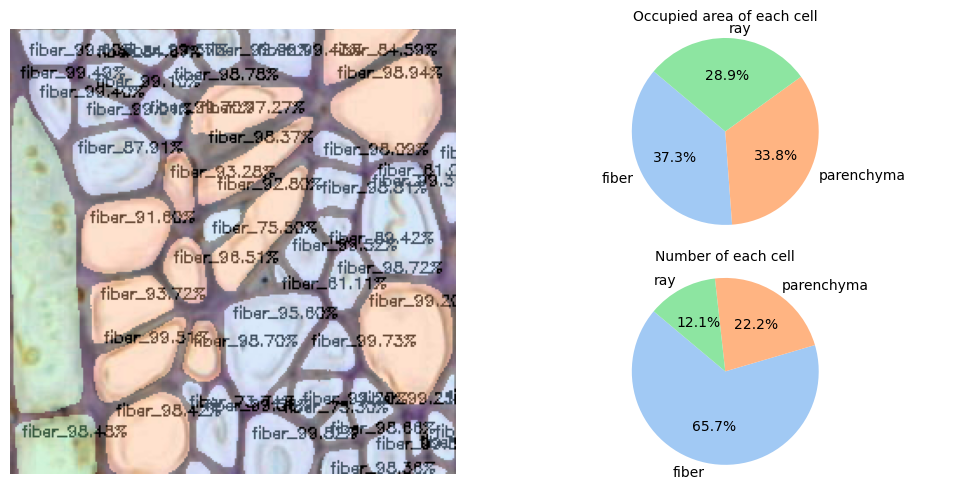

In [10]:
from PIL import Image
import pandas as pd
import seaborn as sns


model.train(False)

i = 2

testfilename = [fl for fl in os.listdir(TEST_DIR) if fl.endswith('.png')]

print('You have ', str(len(testfilename)), \
      ' test images, and you selected image No. ', str(i))

img0 = Image.open(os.path.join(TEST_DIR,testfilename[i])).convert('RGB')
img0 = np.array(img0)
img = cv2.imread(os.path.join(TEST_DIR,testfilename[i]))

result, dfx, pred = predict_single_frame(model, img, IMAGE_SIZE, DEVICE)

image_circle_plot(result, dfx)

The end of script.

an appendix for gifmovie making

- making circular scan of the large image

In [ ]:
'''
imx = Image.open('./dataset/target/Q_acuta_prep_11143_004_3600.png').convert('RGB')

# moving range
theta = 360
rad = np.deg2rad(theta)
drad = rad/360
r = 500

images = []
count = 0
for i in tqdm(range(360)):
    count += 1
    rsinθ = r * np.sin(-drad*count)
    rcosθ = r * np.cos(-drad*count)
    x = rcosθ
    y = rsinθ
    imxp = imx.crop((1250+x, 1250+y, 1250+x+image_size, 1250+y+image_size))
    result_frame, df, _ = predict_single_frame(np.array(imxp))
    dst = image_circle_plot(result_frame, df, save_data=True)
    images.append(dst)

import imageio
imageio.mimsave('./output/result'+str(image_size)+'circle.gif', images,'GIF', fps=5)
'''

 show segmented and detected mask area 

The end of script.